# House Price Prediction
### Internship Task 3 - Machine Learning

This notebook trains and compares three regression models to predict the median house price of a California district using the California Housing dataset.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("muted")


## Load the Data

The dataset is downloaded from scikit-learn on first run. `price` is the median house value in units of **$100,000**.

In [2]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()
df.rename(columns={"MedHouseVal": "price"}, inplace=True)

print("Shape:", df.shape)
df.head()


Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,price
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [5]:
print("Missing values:")
print(df.isnull().sum())


Missing values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
price         0
dtype: int64


## Exploring the Data

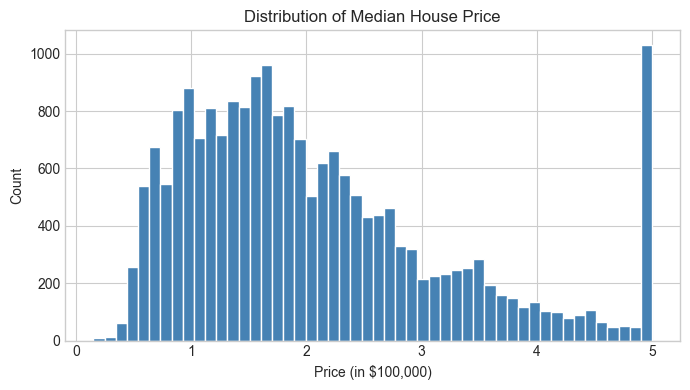

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["price"], bins=50, color="steelblue", edgecolor="white")
ax.set_title("Distribution of Median House Price")
ax.set_xlabel("Price (in $100,000)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


In [7]:
max_price = df["price"].max()
capped = (df["price"] == max_price).sum()
print(f"Maximum price value: {max_price}")
print(f"Rows at the cap: {capped} ({capped / len(df) * 100:.2f}%)")
print("The target is capped, which affects a small share of rows at the top of the price range.")

Maximum price value: 5.00001
Rows at the cap: 965 (4.68%)
The target is capped, which affects a small share of rows at the top of the price range.


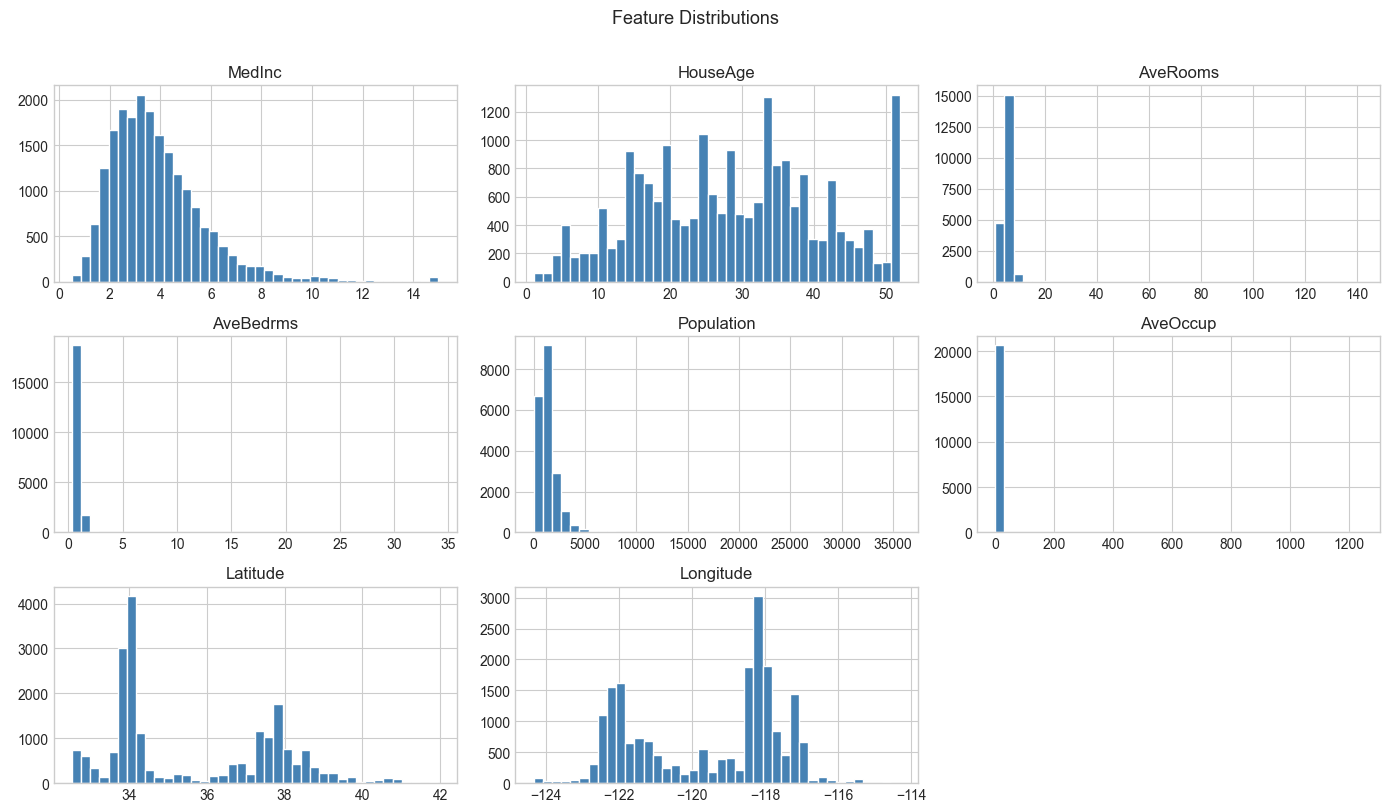

In [8]:
feature_cols = [c for c in df.columns if c != "price"]
df[feature_cols].hist(bins=40, figsize=(14, 8), color="steelblue", edgecolor="white")
plt.suptitle("Feature Distributions", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


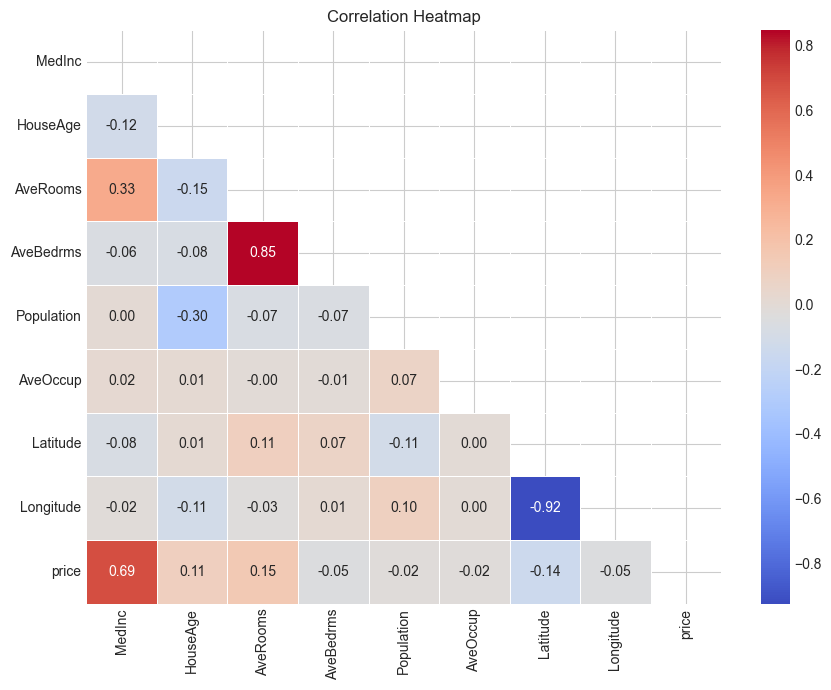

In [9]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", mask=mask, cmap="coolwarm",
            linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()


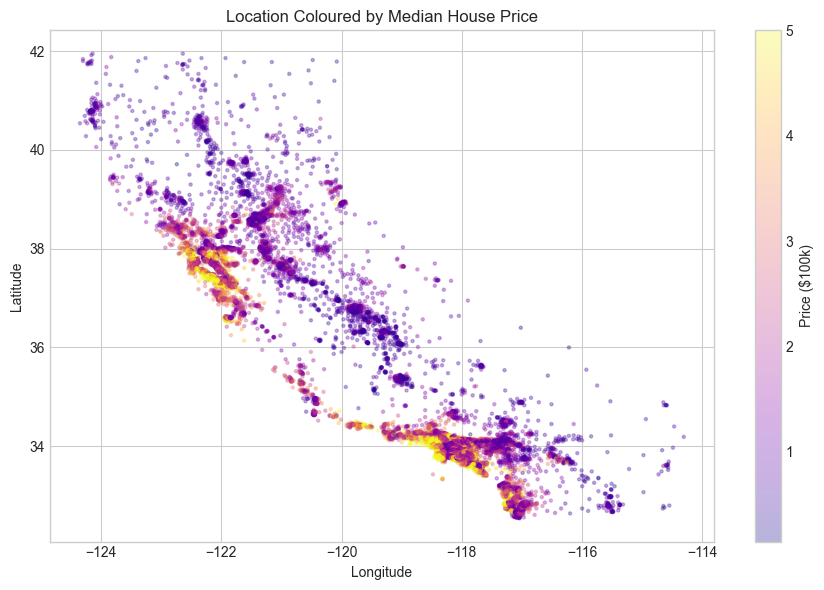

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(df["Longitude"], df["Latitude"], c=df["price"],
                cmap="plasma", alpha=0.3, s=5)
plt.colorbar(sc, ax=ax, label="Price ($100k)")
ax.set_title("Location Coloured by Median House Price")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()


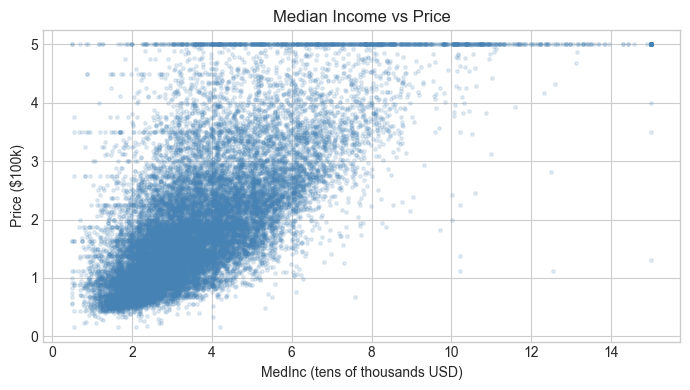

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df["MedInc"], df["price"], alpha=0.15, s=6, color="steelblue")
ax.set_title("Median Income vs Price")
ax.set_xlabel("MedInc (tens of thousands USD)")
ax.set_ylabel("Price ($100k)")
plt.tight_layout()
plt.show()


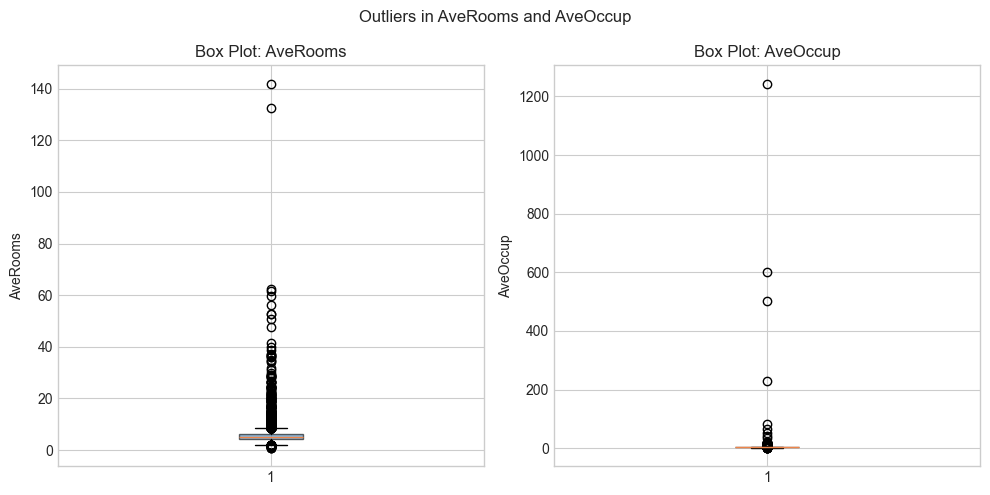

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, col in zip(axes, ["AveRooms", "AveOccup"]):
    ax.boxplot(df[col], vert=True, patch_artist=True,
               boxprops=dict(facecolor="steelblue", alpha=0.6))
    ax.set_title(f"Box Plot: {col}")
    ax.set_ylabel(col)
plt.suptitle("Outliers in AveRooms and AveOccup", fontsize=12)
plt.tight_layout()
plt.show()


**Observations:**
- `MedInc` has the strongest positive correlation with price (r = 0.69). It is clearly the most informative single feature.
- The price is capped at 5.00001 ($500,001), affecting 965 rows (~4.68%). This will introduce bias near the top of the price range.
- `AveRooms` and `AveOccup` have extreme values in some rows. The rows were kept as-is.
- Coastal and Bay Area districts (top-left of the map) cluster at higher prices, confirming that location carries predictive value.

## Preprocessing and Feature Engineering

In [13]:
# No missing values in this dataset.
print("Missing values per column:")
print(df.isnull().sum())


Missing values per column:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
price         0
dtype: int64


In [14]:
# bedroom_ratio captures how many bedrooms there are per room.
# Districts with more bedrooms relative to total rooms tend to be cheaper.
df["bedroom_ratio"] = df["AveBedrms"] / df["AveRooms"]

new_feats = ["bedroom_ratio"]
print("Correlation of new features with price:")
print(df[new_feats + ["price"]].corr()["price"].drop("price"))


Correlation of new features with price:
bedroom_ratio   -0.255624
Name: price, dtype: float64


In [15]:
X = df.drop(columns=["price"])
y = df["price"]

print("Features:", list(X.columns))
print("X shape:", X.shape, "  y shape:", y.shape)


Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'bedroom_ratio']
X shape: (20640, 9)   y shape: (20640,)


## Train/Test Split and Scaling

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train size: {X_train.shape[0]}  Test size: {X_test.shape[0]}")

# Scaler is fit on X_train only and then applied to X_test.
# Fitting on the full dataset before splitting would leak test-set statistics.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)


Train size: 16512  Test size: 4128


## Model Training

### Linear Regression

In [17]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
print("Linear Regression trained.")


Linear Regression trained.


### Decision Tree - choosing max_depth

In [18]:
cv_kf = KFold(n_splits=5, shuffle=True, random_state=42)
depths = [3, 5, 8, 12]

depth_results = []
for d in depths:
    dt = DecisionTreeRegressor(max_depth=d, random_state=42)
    # CV is run on the training set only - the test set is never seen here.
    scores = cross_val_score(dt, X_train_scaled, y_train,
                             cv=cv_kf, scoring="neg_root_mean_squared_error")
    rmse_mean = -scores.mean()
    rmse_std  = scores.std()
    depth_results.append({"max_depth": d, "CV RMSE Mean": rmse_mean, "CV RMSE Std": rmse_std})
    print(f"Depth {d:>2}:  mean RMSE = {rmse_mean:.4f}  std = {rmse_std:.4f}")

best_depth = min(depth_results, key=lambda r: r["CV RMSE Mean"])["max_depth"]
print(f"\nChosen max_depth: {best_depth}")


Depth  3:  mean RMSE = 0.7989  std = 0.0171


Depth  5:  mean RMSE = 0.7221  std = 0.0097


Depth  8:  mean RMSE = 0.6571  std = 0.0111


Depth 12:  mean RMSE = 0.6834  std = 0.0194

Chosen max_depth: 8


In [19]:
tree_model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
tree_model.fit(X_train_scaled, y_train)
print(f"Decision Tree (max_depth={best_depth}) trained.")


Decision Tree (max_depth=8) trained.


### Random Forest

In [20]:
# Scaled data is used here for consistency, even though trees do not require it.
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)
print("Random Forest trained.")


Random Forest trained.


## Evaluation

In [21]:
model_names = [
    "Linear Regression",
    f"Decision Tree (depth={best_depth})",
    "Random Forest"
]
trained_models = [lr_model, tree_model, rf_model]

results = []
predictions = {}

for name, model in zip(model_names, trained_models):
    preds = model.predict(X_test_scaled)
    predictions[name] = preds
    mse  = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_test, preds)
    r2   = r2_score(y_test, preds)
    results.append({"Model": name, "MSE": round(mse, 4), "RMSE": round(rmse, 4),
                    "MAE": round(mae, 4), "R2": round(r2, 4)})

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


                  Model    MSE   RMSE    MAE     R2
      Linear Regression 0.5317 0.7292 0.5261 0.5942
Decision Tree (depth=8) 0.4227 0.6502 0.4483 0.6774
          Random Forest 0.2556 0.5056 0.3285 0.8049


In [22]:
rf_row = results_df[results_df["Model"] == "Random Forest"].iloc[0]
rf_rmse_dollars = rf_row["RMSE"] * 100_000
rf_mae_dollars  = rf_row["MAE"]  * 100_000

print(f"Random Forest RMSE: {rf_row['RMSE']:.4f} units  ->  ${rf_rmse_dollars:,.0f}")
print(f"Random Forest MAE:  {rf_row['MAE']:.4f} units  ->  ${rf_mae_dollars:,.0f}")
print()
print("RMSE penalises large misses more heavily and gives a sense of the typical error size.")
print("MAE is the average absolute difference between predicted and actual price.")

Random Forest RMSE: 0.5056 units  ->  $50,560
Random Forest MAE:  0.3285 units  ->  $32,850

RMSE penalises large misses more heavily and gives a sense of the typical error size.
MAE is the average absolute difference between predicted and actual price.


### Actual vs Predicted

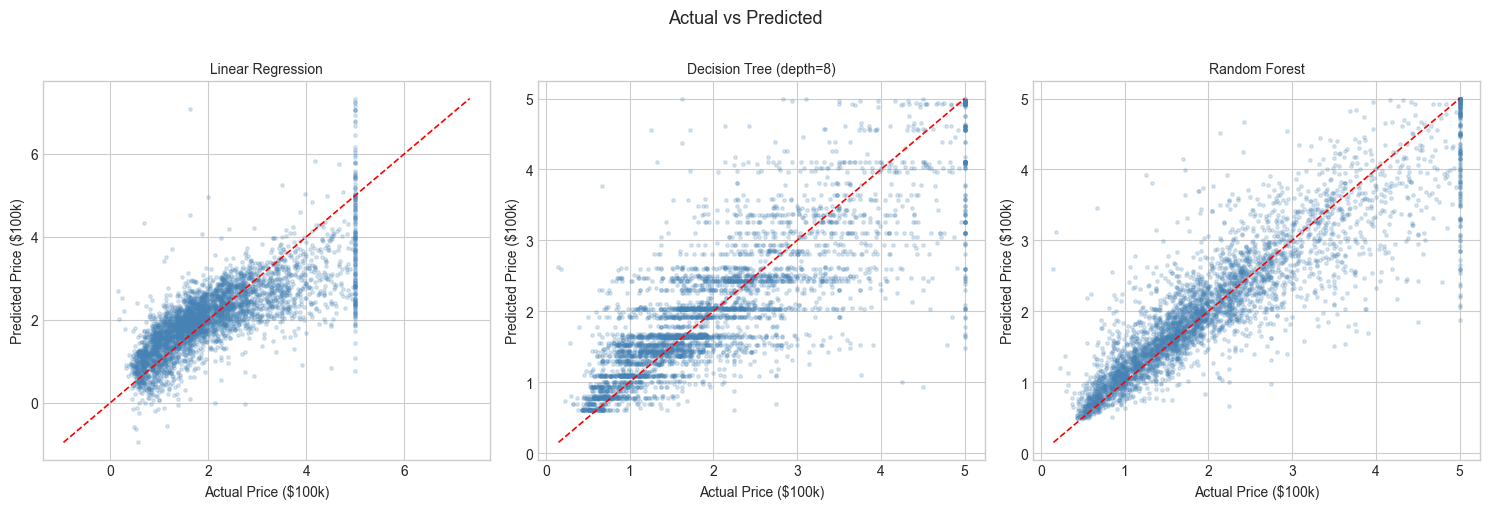

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, preds) in zip(axes, predictions.items()):
    ax.scatter(y_test, preds, alpha=0.2, s=6, color="steelblue")
    lims = [min(y_test.min(), preds.min()), max(y_test.max(), preds.max())]
    ax.plot(lims, lims, "r--", linewidth=1.2)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Actual Price ($100k)")
    ax.set_ylabel("Predicted Price ($100k)")
plt.suptitle("Actual vs Predicted", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


### Residual Plot - Random Forest

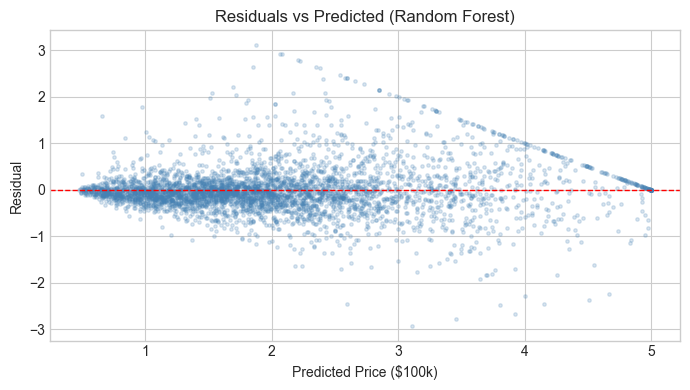

In [24]:
rf_preds = predictions["Random Forest"]
residuals = y_test.values - rf_preds

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(rf_preds, residuals, alpha=0.2, s=6, color="steelblue")
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_title("Residuals vs Predicted (Random Forest)")
ax.set_xlabel("Predicted Price ($100k)")
ax.set_ylabel("Residual")
plt.tight_layout()
plt.show()


### 5-Fold Cross-Validation on Full Dataset

In [25]:
cv_rows = []
for name, model in zip(model_names, [LinearRegression(),
                                      DecisionTreeRegressor(max_depth=best_depth, random_state=42),
                                      RandomForestRegressor(n_estimators=100, random_state=42)]):
    pipe = make_pipeline(StandardScaler(), model)
    rmse_cv = -cross_val_score(pipe, X, y, cv=cv_kf, scoring="neg_root_mean_squared_error")
    r2_cv   =  cross_val_score(pipe, X, y, cv=cv_kf, scoring="r2")
    cv_rows.append({
        "Model": name,
        "CV RMSE Mean": round(rmse_cv.mean(), 4),
        "CV RMSE Std":  round(rmse_cv.std(),  4),
        "CV R2 Mean":   round(r2_cv.mean(),   4),
        "CV R2 Std":    round(r2_cv.std(),    4),
    })

cv_df = pd.DataFrame(cv_rows)
print(cv_df.to_string(index=False))


                  Model  CV RMSE Mean  CV RMSE Std  CV R2 Mean  CV R2 Std
      Linear Regression        0.7197       0.0090      0.6108     0.0106
Decision Tree (depth=8)        0.6503       0.0125      0.6822     0.0099
          Random Forest        0.5043       0.0092      0.8089     0.0069


### Does the Engineered Feature Help?

In [26]:
# Linear Regression without bedroom_ratio
X_train_base = X_train.drop(columns=["bedroom_ratio"])
X_test_base  = X_test.drop(columns=["bedroom_ratio"])

sc_base = StandardScaler()
lr_base = LinearRegression()
lr_base.fit(sc_base.fit_transform(X_train_base), y_train)
preds_base = lr_base.predict(sc_base.transform(X_test_base))

eng_df = pd.DataFrame([
    {"Features": "Without bedroom_ratio",
     "RMSE": round(np.sqrt(mean_squared_error(y_test, preds_base)), 4),
     "R2":   round(r2_score(y_test, preds_base), 4)},
    {"Features": "With bedroom_ratio",
     "RMSE": results_df.loc[results_df["Model"] == "Linear Regression", "RMSE"].values[0],
     "R2":   results_df.loc[results_df["Model"] == "Linear Regression", "R2"].values[0]},
])
print(eng_df.to_string(index=False))

rmse_diff = round(eng_df.loc[0, "RMSE"] - eng_df.loc[1, "RMSE"], 4)
r2_diff   = round(eng_df.loc[1, "R2"]   - eng_df.loc[0, "R2"],   4)
print(f"\nOn this one split, adding bedroom_ratio lowers RMSE by {rmse_diff} and raises R2 by {r2_diff}.")

             Features   RMSE     R2
Without bedroom_ratio 0.7456 0.5758
   With bedroom_ratio 0.7292 0.5942

On this one split, adding bedroom_ratio lowers RMSE by 0.0164 and raises R2 by 0.0184.


## Which Features Matter

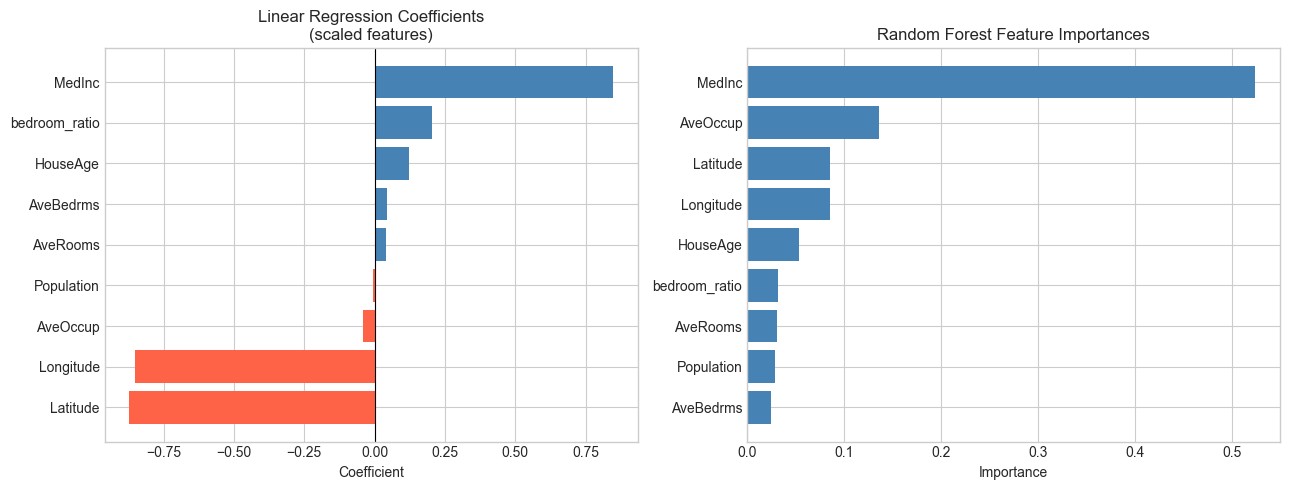

In [27]:
feature_names = list(X.columns)

lr_coefs = pd.Series(lr_model.coef_, index=feature_names).sort_values()
rf_imps  = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Linear Regression coefficients
colors_lr = ["tomato" if v < 0 else "steelblue" for v in lr_coefs.values]
axes[0].barh(lr_coefs.index, lr_coefs.values, color=colors_lr)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Linear Regression Coefficients\n(scaled features)")
axes[0].set_xlabel("Coefficient")

# Random Forest importances
axes[1].barh(rf_imps.index[::-1], rf_imps.values[::-1], color="steelblue")
axes[1].set_title("Random Forest Feature Importances")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.show()


`MedInc` has the largest positive coefficient in Linear Regression and the highest importance in the Random Forest, at about 52%.
In Linear Regression, `Latitude` and `Longitude` carry large negative coefficients of roughly the same size as `MedInc`'s positive one. Both also rank in the top four in the Random Forest, so location is important in both models.
`AveOccup` ranks second in the Random Forest with about 14% importance.

## Looking at the Mistakes

In [28]:
rf_preds_arr = predictions["Random Forest"]
errors_df = X_test.copy()
errors_df["Actual"]    = y_test.values
errors_df["Predicted"] = rf_preds_arr
errors_df["Abs_Error"] = np.abs(y_test.values - rf_preds_arr)

worst5 = (errors_df
          .sort_values("Abs_Error", ascending=False)
          .head(5)[["Actual", "Predicted", "Abs_Error", "MedInc", "Latitude", "Longitude"]]
          .round(4))
print(worst5.to_string())


       Actual  Predicted  Abs_Error  MedInc  Latitude  Longitude
6688    5.000     1.8720     3.1280  0.4999     34.15    -118.08
5887    0.175     3.1108     2.9358  2.3667     34.15    -118.33
12069   5.000     2.0657     2.9343  4.2386     33.83    -117.55
12389   5.000     2.0843     2.9158  3.7727     33.75    -116.43
17306   5.000     2.2048     2.7952  2.7275     34.38    -119.55


Four of the five largest errors have an actual price at or very near the cap (5.00001). The model consistently under-predicts these,
which makes sense: the true value could be anything above $500,000 but the training data shows 5.00001.
The fifth row has an actual price of 0.175 ($17,500), which the model over-predicts significantly - another hard edge case.

## Predict on a New House

In [29]:
new_district = pd.DataFrame([{
    "MedInc":     4.5,
    "HouseAge":   25.0,
    "AveRooms":   5.5,
    "AveBedrms":  1.1,
    "Population": 1500.0,
    "AveOccup":   3.0,
    "Latitude":   34.0,
    "Longitude":  -118.3,
}])
# Compute the same engineered feature used during training.
new_district["bedroom_ratio"] = new_district["AveBedrms"] / new_district["AveRooms"]

# Use the already-fitted scaler - no refitting.
new_scaled = scaler.transform(new_district)
predicted_price = rf_model.predict(new_scaled)[0]

print(f"Predicted median house value: {predicted_price:.4f} (units of $100,000)")
print(f"Equivalent to approximately: ${predicted_price * 100_000:,.0f}")
print()
print("Note: this is a district-level estimate, not the price of a single house.")


Predicted median house value: 2.3014 (units of $100,000)
Equivalent to approximately: $230,138

Note: this is a district-level estimate, not the price of a single house.


## Conclusion

- Random Forest achieved the lowest test-set RMSE (0.5056) and highest R2 (0.8049). The Decision Tree (depth=8) scored RMSE=0.6502, R2=0.6774, and Linear Regression scored RMSE=0.7292, R2=0.5942. The 5-fold cross-validation results agree with this ranking (RF CV RMSE=0.5043, R2=0.8089).
- Random Forest's RMSE of 0.5056 units corresponds to about $50,560. RMSE penalises large misses more, so the average absolute error (MAE) is lower: $32,850. Both figures are in units of $100,000 scaled back to dollars.
- Linear Regression performed noticeably worse than both tree-based models. One possible reason is that income, location and occupancy interact in non-linear ways that trees can capture and a linear model cannot. I did not test this directly.
- The price cap at $500,001 affects 4.68% of rows and causes the model to under-predict for expensive districts. `AveRooms` and `AveOccup` contain extreme values. The data comes from the 1990 census and is at district level, so it reflects neither current prices nor individual properties.
- One improvement worth trying: remove or separately model the capped rows, or apply a log transform to skewed features like `AveOccup`.